In [1]:
'''2:
Distanza (Knorr, KNN (Ramaswamy / Pizzuti / ln-degree))
Densità (LOF, COF, INFLO)
Clustering (CBLOF)'''

from collections import Counter
from collections import defaultdict

# Base
import math as m

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)
from pyod.models.knn import KNN
from scipy.spatial.distance import pdist, squareform
from tqdm import tqdm

In [2]:
df = pd.read_csv("df.csv")

# Train & Test
train_set = pd.read_csv("train_set.csv")
test_set = pd.read_csv("test_set.csv")

# Imputed
train_imputed = pd.read_csv("train_imputed.csv")
test_imputed = pd.read_csv("test_imputed.csv")

train_imputed_rf = pd.read_csv("train_imputed_rf.csv")
test_imputed_rf = pd.read_csv("test_imputed_rf.csv")

tt = np.concatenate([train_imputed, test_imputed], axis=0)

df_unito = pd.DataFrame(tt, columns=train_imputed.columns)



/var/folders/dx/gml1dzlj4hv40xclhd6scg5r0000gn/T/ipykernel_41414/2329004918.py:1: DtypeWarning: Columns (53) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("df.csv")


In [3]:
# come conviene gestire le stagioni? trasformarle in 1234 non ha senso in questo caso
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

X=df_unito.values
y=np.array(df_unito['sii'])
X_standard=standard_scaler.fit_transform(X)
y = y.astype(int)

X_train, X_test, _, _ = train_test_split(X_standard, y, test_size=0.3, random_state=0)

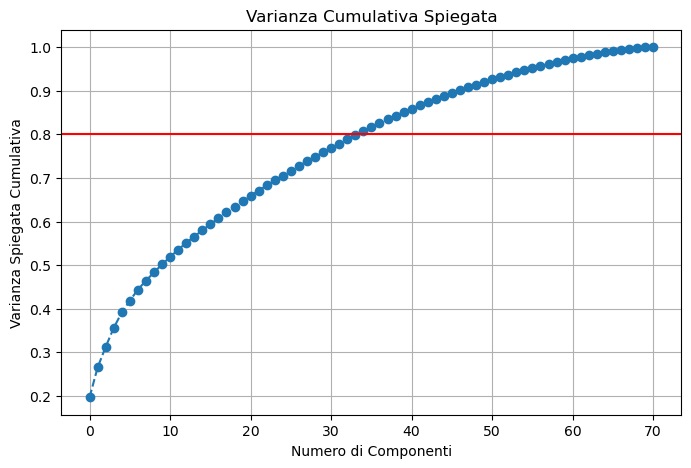

In [4]:
# Calcoliamo la PCA su tutte le componenti possibili per vedere il quadro completo
pca_full = PCA().fit(X_standard)
plt.figure(figsize=(8, 5))
plt.plot(np.cumsum(pca_full.explained_variance_ratio_), marker='o', linestyle='--')
plt.axhline(y=0.8, color='r', linestyle='-') # Linea del 80%
plt.title('Varianza Cumulativa Spiegata')
plt.xlabel('Numero di Componenti')
plt.ylabel('Varianza Spiegata Cumulativa')
plt.grid()
plt.show()

#quindi praticamente inutile

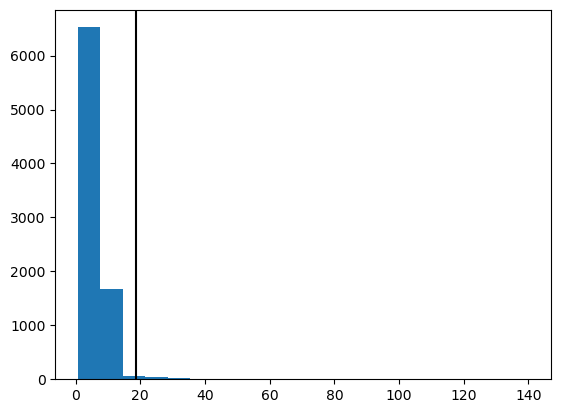

Numero di outlier trovati: 82 (0.99%)


In [5]:
#=====KNN======
'''General models
• Take the kNN distance of a point as its outlier score [Ramaswamy et al 2000]
• Aggregate the distances of a point to all its 1NN, 2NN, …, kNN as an outlier
score [Angiulli and Pizzuti 2002]'''

#n=round(m.sqrt(len(df_unito)))
n=76
clf = KNN(contamination=0.01, n_neighbors=n, method='mean') 
#scritto nella descrizione del metodo e consigliato da guidotti: 'mean': use the average of all k neighbors as the outlier score

clf.fit(X_standard)

outliers_knn = clf.predict(X_standard)
np.unique(outliers_knn, return_counts=True)

plt.hist(clf.decision_scores_, bins=20)
plt.axvline(np.min(clf.decision_scores_[np.where(outliers_knn==1)]), c='k')
plt.show()

n_outliers_knn = np.sum(outliers_knn)
print(f"Numero di outlier trovati: {int(n_outliers_knn)} ({n_outliers_knn/len(df_unito)*100:.2f}%)")

#1% di outliers come scritto nelle slide (contamination)

/var/folders/dx/gml1dzlj4hv40xclhd6scg5r0000gn/T/ipykernel_41414/729510672.py:22: DeprecationWarning: Calling nonzero on 0d arrays is deprecated, as it behaves surprisingly. Use `atleast_1d(cond).nonzero()` if the old behavior was intended. If the context of this warning is of the form `arr[nonzero(cond)]`, just use `arr[cond]`.
  plt.axvline(np.max(rknn_scores[np.where(out==1)]), c='k', linestyle='--')


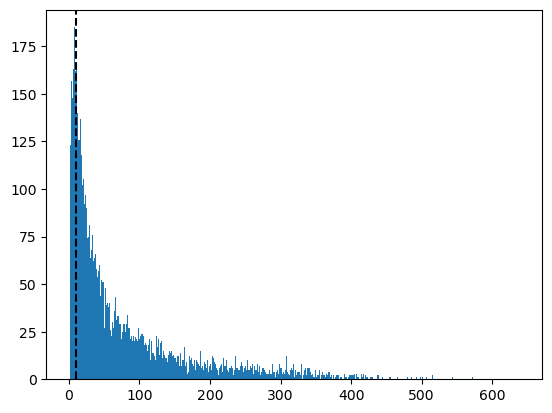

Numero di outlier trovati: 107 (1.29%)


In [6]:
#=====RKNN======
# 1. Trova i k-vicini per ogni punto
k = 76
nbrs = NearestNeighbors(n_neighbors=k).fit(X_standard)
distances, indices = nbrs.kneighbors(X_standard)

# 2. Conta quante volte ogni indice compare nella matrice dei vicini
# 'indices' contiene gli indici dei k vicini per ogni riga
flat_indices = indices.flatten()
counts = np.bincount(flat_indices, minlength=len(X_standard))

# 3. Lo score RkNN è il conteggio (invertito)
# Più il conteggio è basso, più il punto è un outlier
rknn_scores = counts

out= np.percentile(rknn_scores, q=1)

outliers_rknn = np.zeros(len(rknn_scores))
outliers_rknn[rknn_scores <= out] = 1

plt.hist(rknn_scores, bins=range(int(np.max(rknn_scores))))
plt.axvline(np.max(rknn_scores[np.where(out==1)]), c='k', linestyle='--')
plt.show()

n_outliers_rknn = np.sum(outliers_rknn)
print(f"Numero di outlier trovati: {int(n_outliers_rknn)} ({n_outliers_rknn/len(df_unito)*100:.2f}%)")
#molto in dubbio. mi da 11% di outliers pur impostando 1. secondo gemini molti valori tutti uguali e quindi si arriva all'11


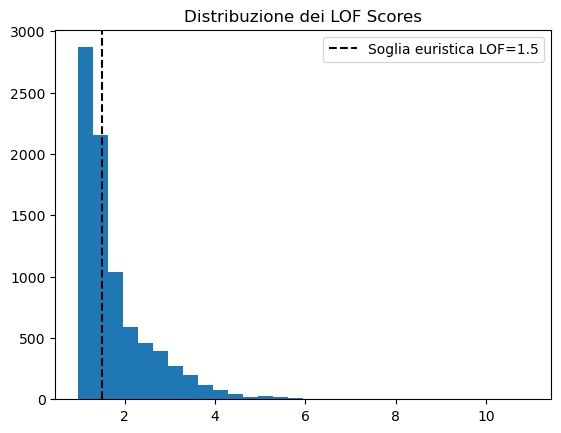

Numero di outlier trovati: 84 (1.01%)


In [7]:
# ==== ## LOF (sklearn) ====
from sklearn.neighbors import LocalOutlierFactor

'''PRESO DA SKLEARN: By default, LocalOutlierFactor is only meant to be used for outlier detection (
novelty=False). Set novelty to True if you want to use LocalOutlierFactor for 
novelty detection. In this case be aware that you should only use predict, 
decision_function and score_samples on new unseen data and not on the training 
set; and note that the results obtained this way may differ from the standard LOF 
results'''

# Parametri: n_neighbors solitamente > 10-20 per avere una stima stabile della densità
lof = LocalOutlierFactor(n_neighbors=76, contamination=0.01, novelty=False)

y_pred_lof = lof.fit_predict(X_standard) 

# Gli score sono negativi (più sono bassi, più è outlier)
# Li invertiamo per averli positivi (LOF > 1 indica potenziale outlier)
lof_scores = -lof.negative_outlier_factor_

# Identifichiamo gli indici degli outlier (y_pred == -1)

outliers_lof_idx = np.where(y_pred_lof == -1)

plt.hist(lof_scores, bins=30)
#non si capisce bene come vada scelto il limite
plt.axvline(x=1.5, color='black', linestyle='--', label='Soglia euristica LOF=1.5') 
#plt.hist(clf.negative_outlier_factor_, bins=20)
#plt.axvline(np.min(clf.negative_outlier_factor_[np.where(outliers==1)]), c='k')# Tipico valore soglia
plt.title("Distribuzione dei LOF Scores")
plt.legend()
plt.show()

n_outliers_lof = np.count_nonzero(outliers_lof_idx)
print(f"Numero di outlier trovati: {int(n_outliers_lof)} ({n_outliers_lof/len(df_unito)*100:.2f}%)")

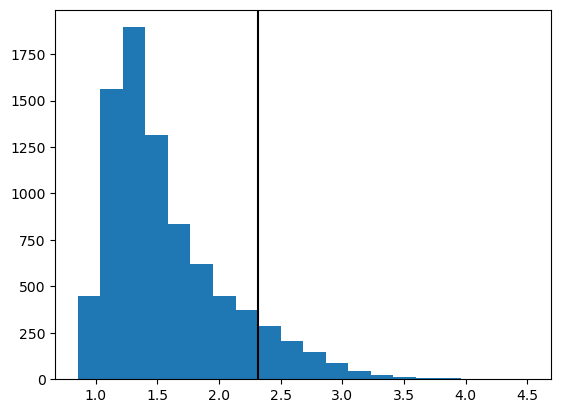

Numero di outlier trovati: 832 (10.00%)


In [8]:
#==== COF ====
from pyod.models.cof import COF
clf = COF(contamination=0.1, method='fast', n_neighbors=76)
clf.fit(X_standard)

outliers_cof = clf.predict(X_standard)
#np.unique(outliers_cof, return_counts=True)

plt.hist(clf.decision_scores_, bins=20)
plt.axvline(np.min(clf.decision_scores_[np.where(outliers_cof==1)]), c='k')
plt.show()

n_outliers_cof = np.count_nonzero(outliers_cof)
print(f"Numero di outlier trovati: {int(n_outliers_cof)} ({n_outliers_cof/len(df_unito)*100:.2f}%)")

In [9]:
#==== DBSCAN non è che sia incredibile====

from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=5, min_samples=10)
dbscan.fit(X_standard)

#np.unique(dbscan.labels_, return_counts=True)

df.loc[np.where(dbscan.labels_==-1)]

,Basic_Demos-Enroll_Season,Basic_Demos-Age,Basic_Demos-Sex,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Height,Physical-Weight,Physical-Waist_Circumference,...,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,SDS-Season,SDS-SDS_Total_Raw,SDS-SDS_Total_T,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,sii,Fitness_Endurance-Tempo_totale
0,Fall,5,0,Winter,51.0,Fall,16.877316,46.00,50.8,26.00,...,2.0,4.0,55.0,NaN,NaN,NaN,Fall,3.0,2.0,448.0
2,Summer,10,1,Fall,71.0,Fall,16.648696,56.50,75.6,NaN,...,1.0,1.0,28.0,Fall,38.0,54.0,Summer,2.0,0.0,453.0
4,Spring,18,1,Summer,65.0,NaN,17.937682,NaN,77.0,26.00,...,NaN,NaN,NaN,NaN,NaN,NaN,Spring,1.0,0.0,NaN
5,Spring,13,1,Winter,50.0,Summer,22.279952,59.50,112.2,26.00,...,2.0,1.0,34.0,Summer,40.0,56.0,Spring,0.0,1.0,448.0
6,Fall,10,0,Spring,NaN,Fall,19.660760,55.00,84.6,NaN,...,1.0,0.0,20.0,Winter,27.0,40.0,Fall,3.0,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8311,Winter,6,1,Winter,65.5,Fall,18.932165,54.48,48.8,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Spring,0.0,0.0,NaN
8312,Fall,12,1,Winter,NaN,Fall,19.713726,NaN,105.7,29.50,...,NaN,NaN,NaN,NaN,NaN,NaN,Fall,2.0,0.0,NaN
8314,Spring,7,1,Spring,NaN,Fall,16.130585,46.07,49.0,22.25,...,NaN,NaN,NaN,Summer,38.5,55.0,Spring,0.0,0.0,NaN
8316,Winter,10,1,Winter,70.0,Winter,40.937571,49.56,47.2,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Spring,2.0,0.0,528.0


CBLOF(alpha=0.9, beta=5, check_estimator=False, clustering_estimator=None,
   contamination=0.01, n_clusters=8, n_jobs=None, random_state=None,
   use_weights=False)


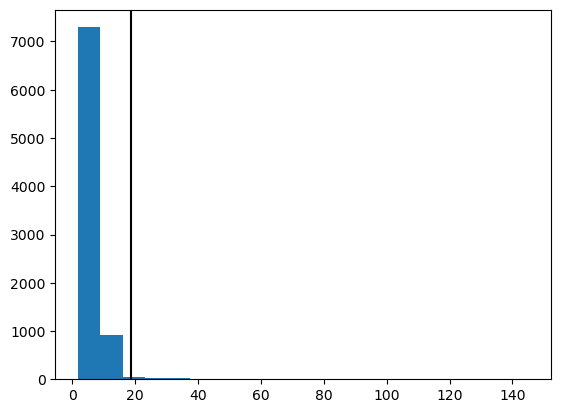

Numero di outlier trovati: 84 (1.01%)


In [10]:
#==== CBLOF ====
from pyod.models.cblof import CBLOF

clf = CBLOF(contamination=0.01)
print(clf.fit(X_standard))

outliers_cblof = clf.predict(X_standard)
np.unique(outliers_cblof, return_counts=True)

plt.hist(clf.decision_scores_, bins=20)
plt.axvline(np.min(clf.decision_scores_[np.where(outliers_cblof==1)]), c='k')
plt.show()

n_outliers_cblof = np.sum(outliers_cblof)
print(f"Numero di outlier trovati: {int(n_outliers_cblof)} ({n_outliers_cblof/len(df_unito)*100:.2f}%)")

Numero di bin suggerito: 15
HBOS(alpha=0.1, contamination=0.1, n_bins=14, tol=0.5)


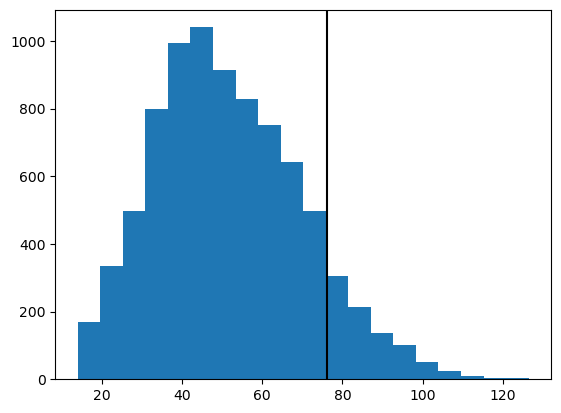

Numero di outlier trovati: 832 (10.00%)


In [11]:
# ==== HBOS ====

from pyod.models.hbos import HBOS

n = len(X_standard)

# Utilizzando la libreria math
k = m.ceil(m.log2(n) + 1)

# Utilizzando numpy (se stai già lavorando con array)
k = int(np.ceil(np.log2(n) + 1))

print(f"Numero di bin suggerito: {k}")
clf = HBOS(n_bins=14)
print(clf.fit(X_standard))
clf.decision_scores_

outliers_hdbs = clf.predict(X_standard)
np.unique(outliers_hdbs, return_counts=True)

plt.hist(clf.decision_scores_, bins=20)
plt.axvline(np.min(clf.decision_scores_[np.where(outliers_hdbs==1)]), c='k')
plt.show()
clf.decision_function(X_standard)
n_outliers_hdbs = np.sum(outliers_hdbs)
print(f"Numero di outlier trovati: {int(n_outliers_hdbs)} ({n_outliers_hdbs/len(df_unito)*100:.2f}%)")

In [12]:
#=== Likelihood Appraoch ===

'''import numpy as np
from scipy import stats

def norm_dist(x, mu, sigma):
    return 1/(np.sqrt(2*np.pi)*sigma) * np.e**(-((x-mu)**2)/(2*sigma**2))
              
def unif_dist(x, n):
    return 1/n

M = np.copy(X_standard)
A = list()
muM = np.mean(M)
sigmaM = np.std(M)

M = np.copy(X_standard)
A = []
lambda_par = 0.3

muM = np.mean(M)
sigmaM = np.std(M)
sizeA = len(A)

sumM = np.sum([norm_dist(x, muM, sigmaM) for x in M])

sumA = np.sum([unif_dist(x, sizeA) for x in A])

ll = (len(M) * np.log(1-lambda_par) + sumM + len(A) * np.log(lambda_par) + sumA)
print(ll)

c = 0.2
for i, x in enumerate(X_standard):
    A.append(x)
    M = np.array([xo for j, xo in enumerate(X_standard) if i!=j])
    muM = np.mean(M)
    sigmaM = np.std(M)
    sizeA = len(A)
    sumM = np.sum([norm_dist(x, muM, sigmaM) for x in M])
    sumA = np.sum([unif_dist(x, sizeA) for x in A])
    ll_xi = (len(M) * np.log(1-lambda_par) + sumM + len(A) * np.log(lambda_par) + sumA)
    delta_ll = abs(ll - ll_xi)
    print(i, delta_ll, 'outlier' if delta_ll > c else 'inlier')
    M = np.copy(X_standard)
    A = list()'''

"import numpy as np\nfrom scipy import stats\n\ndef norm_dist(x, mu, sigma):\n    return 1/(np.sqrt(2*np.pi)*sigma) * np.e**(-((x-mu)**2)/(2*sigma**2))\n              \ndef unif_dist(x, n):\n    return 1/n\n\nM = np.copy(X_standard)\nA = list()\nmuM = np.mean(M)\nsigmaM = np.std(M)\n\nM = np.copy(X_standard)\nA = []\nlambda_par = 0.3\n\nmuM = np.mean(M)\nsigmaM = np.std(M)\nsizeA = len(A)\n\nsumM = np.sum([norm_dist(x, muM, sigmaM) for x in M])\n\nsumA = np.sum([unif_dist(x, sizeA) for x in A])\n\nll = (len(M) * np.log(1-lambda_par) + sumM + len(A) * np.log(lambda_par) + sumA)\nprint(ll)\n\nc = 0.2\nfor i, x in enumerate(X_standard):\n    A.append(x)\n    M = np.array([xo for j, xo in enumerate(X_standard) if i!=j])\n    muM = np.mean(M)\n    sigmaM = np.std(M)\n    sizeA = len(A)\n    sumM = np.sum([norm_dist(x, muM, sigmaM) for x in M])\n    sumA = np.sum([unif_dist(x, sizeA) for x in A])\n    ll_xi = (len(M) * np.log(1-lambda_par) + sumM + len(A) * np.log(lambda_par) + sumA)\n    de

In [13]:
#==== EllEnv ====

from sklearn.covariance import EllipticEnvelope

ellenv = EllipticEnvelope(random_state=0, contamination=0.01)
ellenv.fit(X_standard)

# predict returns 1 for an inlier and -1 for an outlier
outliers_ellenv = ellenv.predict(X_standard)

#print (outliers_ellenv)
np.unique(outliers_ellenv, return_counts=True)

n_outliers_ellenv = np.sum(outliers_ellenv)
print(f"Numero di outlier trovati: {int(n_outliers_ellenv)} ({n_outliers_ellenv/len(df_unito)*100:.2f}%)")

Numero di outlier trovati: 8151 (97.98%)
